# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# After mounting your drive, your content will be accessible in /content/drive
# For example, if you have a folder named 'MyProject' in your Drive, you can list its contents like this:
project_folder_path = '/content/drive/My Drive/Colab Notebooks/input' # Adjust this path to your specific folder

if os.path.exists(project_folder_path):
    print(f"Contents of '{project_folder_path}':")
    for item in os.listdir(project_folder_path):
        print(item)
else:
    print(f"Folder '{project_folder_path}' not found. Please ensure the path is correct and the folder exists in your Google Drive.")

Contents of '/content/drive/My Drive/Colab Notebooks/input':
high_diamond_ranked_10min.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_style('darkgrid')

plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/input/high_diamond_ranked_10min.csv')
df.head()

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,...,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,...,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,...,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,...,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,...,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [5]:
df.shape

(9879, 40)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9879 entries, 0 to 9878
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   gameId                        9879 non-null   int64  
 1   blueWins                      9879 non-null   int64  
 2   blueWardsPlaced               9879 non-null   int64  
 3   blueWardsDestroyed            9879 non-null   int64  
 4   blueFirstBlood                9879 non-null   int64  
 5   blueKills                     9879 non-null   int64  
 6   blueDeaths                    9879 non-null   int64  
 7   blueAssists                   9879 non-null   int64  
 8   blueEliteMonsters             9879 non-null   int64  
 9   blueDragons                   9879 non-null   int64  
 10  blueHeralds                   9879 non-null   int64  
 11  blueTowersDestroyed           9879 non-null   int64  
 12  blueTotalGold                 9879 non-null   int64  
 13  blu

In [7]:
df.describe()

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
count,9.879000e+03,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,...,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000
mean,4.500084e+09,0.499038,22.288288,2.824881,0.504808,6.183925,6.137666,6.645106,0.549954,0.361980,...,0.043021,16489.041401,6.925316,17961.730438,217.349226,51.313088,-14.414111,33.620306,21.734923,1648.904140
std,2.757328e+07,0.500024,18.019177,2.174998,0.500002,3.011028,2.933818,4.064520,0.625527,0.480597,...,0.216900,1490.888406,0.305311,1198.583912,21.911668,10.027885,2453.349179,1920.370438,2.191167,149.088841
min,4.295358e+09,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,11212.000000,4.800000,10465.000000,107.000000,4.000000,-11467.000000,-8348.000000,10.700000,1121.200000
25%,4.483301e+09,0.000000,14.000000,1.000000,0.000000,4.000000,4.000000,4.000000,0.000000,0.000000,...,0.000000,15427.500000,6.800000,17209.500000,203.000000,44.000000,-1596.000000,-1212.000000,20.300000,1542.750000
50%,4.510920e+09,0.000000,16.000000,3.000000,1.000000,6.000000,6.000000,6.000000,0.000000,0.000000,...,0.000000,16378.000000,7.000000,17974.000000,218.000000,51.000000,-14.000000,28.000000,21.800000,1637.800000
75%,4.521733e+09,1.000000,20.000000,4.000000,1.000000,8.000000,8.000000,9.000000,1.000000,1.000000,...,0.000000,17418.500000,7.200000,18764.500000,233.000000,57.000000,1585.500000,1290.500000,23.300000,1741.850000
max,4.527991e+09,1.000000,250.000000,27.000000,1.000000,22.000000,22.000000,29.000000,2.000000,1.000000,...,2.000000,22732.000000,8.200000,22269.000000,289.000000,92.000000,10830.000000,9333.000000,28.900000,2273.200000


### Duplicadas

In [8]:
df.duplicated().sum()
...
df_clean = df.copy()

# Removendo colunas desnecessárias (Não estou mais removendo!!, isso está aqui so por está mas não utilizo mais)

In [9]:
cols = ['gameId', 'redFirstBlood', 'redKills', 'redEliteMonsters', 'redDragons','redTotalMinionsKilled',
       'redTotalJungleMinionsKilled', 'redGoldDiff', 'redExperienceDiff', 'redCSPerMin', 'redGoldPerMin', 'redHeralds',
       'blueGoldDiff', 'blueExperienceDiff', 'blueCSPerMin', 'blueGoldPerMin', 'blueTotalMinionsKilled']
df_clean = df_clean.drop(cols, axis = 1)

In [10]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9879 entries, 0 to 9878
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   blueWins                      9879 non-null   int64  
 1   blueWardsPlaced               9879 non-null   int64  
 2   blueWardsDestroyed            9879 non-null   int64  
 3   blueFirstBlood                9879 non-null   int64  
 4   blueKills                     9879 non-null   int64  
 5   blueDeaths                    9879 non-null   int64  
 6   blueAssists                   9879 non-null   int64  
 7   blueEliteMonsters             9879 non-null   int64  
 8   blueDragons                   9879 non-null   int64  
 9   blueHeralds                   9879 non-null   int64  
 10  blueTowersDestroyed           9879 non-null   int64  
 11  blueTotalGold                 9879 non-null   int64  
 12  blueAvgLevel                  9879 non-null   float64
 13  blu

### Renomeando o atributo alvo para facilitar a interpretação (Não estou renomeando pois não achei necessidade, os atributos estão bem nomeados para precisar)

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
df["doenca_cardiaca"] = np.where(df["num"] > 0, "Cardíaco", "Normal")
df["doenca_cardiaca"].value_counts()
df.drop(columns=["num"], inplace=True)
df.head()

KeyError: 'num'

## 2. Dados Faltantes

In [11]:
df.isna().sum()

,0
gameId,0
blueWins,0
blueWardsPlaced,0
blueWardsDestroyed,0
blueFirstBlood,0
blueKills,0
blueDeaths,0
blueAssists,0
blueEliteMonsters,0
blueDragons,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: não tem :D (serio não tem, não sei mais o que justificar)

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [12]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [13]:
if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
                rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    print("Não há colunas suficientes com valores ausentes (precisa de pelo menos duas) para criar a tabela de contingência e o heatmap de ausências.")
    if len(cols_com_ausentes) == 1:
        print(f"Apenas a coluna '{cols_com_ausentes[0]}' possui valores ausentes.")
    else:
        print("Não há colunas com valores ausentes no DataFrame.")

Não há colunas suficientes com valores ausentes (precisa de pelo menos duas) para criar a tabela de contingência e o heatmap de ausências.
Não há colunas com valores ausentes no DataFrame.


**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes? Então, não tem :p

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [14]:
df.describe()

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
count,9.879000e+03,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,...,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000,9879.000000
mean,4.500084e+09,0.499038,22.288288,2.824881,0.504808,6.183925,6.137666,6.645106,0.549954,0.361980,...,0.043021,16489.041401,6.925316,17961.730438,217.349226,51.313088,-14.414111,33.620306,21.734923,1648.904140
std,2.757328e+07,0.500024,18.019177,2.174998,0.500002,3.011028,2.933818,4.064520,0.625527,0.480597,...,0.216900,1490.888406,0.305311,1198.583912,21.911668,10.027885,2453.349179,1920.370438,2.191167,149.088841
min,4.295358e+09,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,11212.000000,4.800000,10465.000000,107.000000,4.000000,-11467.000000,-8348.000000,10.700000,1121.200000
25%,4.483301e+09,0.000000,14.000000,1.000000,0.000000,4.000000,4.000000,4.000000,0.000000,0.000000,...,0.000000,15427.500000,6.800000,17209.500000,203.000000,44.000000,-1596.000000,-1212.000000,20.300000,1542.750000
50%,4.510920e+09,0.000000,16.000000,3.000000,1.000000,6.000000,6.000000,6.000000,0.000000,0.000000,...,0.000000,16378.000000,7.000000,17974.000000,218.000000,51.000000,-14.000000,28.000000,21.800000,1637.800000
75%,4.521733e+09,1.000000,20.000000,4.000000,1.000000,8.000000,8.000000,9.000000,1.000000,1.000000,...,0.000000,17418.500000,7.200000,18764.500000,233.000000,57.000000,1585.500000,1290.500000,23.300000,1741.850000
max,4.527991e+09,1.000000,250.000000,27.000000,1.000000,22.000000,22.000000,29.000000,2.000000,1.000000,...,2.000000,22732.000000,8.200000,22269.000000,289.000000,92.000000,10830.000000,9333.000000,28.900000,2273.200000


In [15]:
VARS_QUANT = ["blueWardsPlaced", "blueWardsDestroyed", "blueKills", "blueDeaths", "blueAssists", "blueEliteMonsters", "blueTotalGold", "blueAvgLevel",
              "blueTotalExperience", "blueTotalMinionsKilled", "blueTotalJungleMinionsKilled", "blueGoldDiff", "blueExperienceDiff", "blueCSPerMin", "blueGoldPerMin",
              "redWardsPlaced", "redWardsDestroyed", "redKills", "redDeaths", "redAssists", "redEliteMonsters", "redTotalGold", "redAvgLevel",
              "redTotalExperience", "redTotalMinionsKilled", "redTotalJungleMinionsKilled", "redGoldDiff", "redExperienceDiff", "redCSPerMin", "redGoldPerMin"
              ]
VARS_QUALI = ["blueWins", "blueFirstBlood", "blueDragons", "blueHeralds", "blueTowersDestroyed", "redFirstBlood", "redDragons", "redHeralds", "redTowersDestroyed"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
blueWardsPlaced,22.29,16.00,18.02,5.00,250.00,4.14,23.44
blueWardsDestroyed,2.82,3.00,2.17,0.00,27.00,2.85,17.20
blueKills,6.18,6.00,3.01,0.00,22.00,0.54,0.26
blueDeaths,6.14,6.00,2.93,0.00,22.00,0.51,0.21
blueAssists,6.65,6.00,4.06,0.00,29.00,0.89,1.16
blueEliteMonsters,0.55,0.00,0.63,0.00,2.00,0.69,-0.50
blueTotalGold,16503.46,16398.00,1535.45,10730.00,23701.00,0.47,0.48
blueAvgLevel,6.92,7.00,0.31,4.60,8.00,-0.34,1.12
blueTotalExperience,17928.11,17951.00,1200.52,10098.00,22224.00,-0.25,0.68
blueTotalMinionsKilled,216.70,218.00,21.86,90.00,283.00,-0.27,0.17


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)? As variaveis relacionadas a wards placed e wards destroyed, tanto do time azul quanto do vermelho, são as mais assimetricas e com caudas pesadas. Isso sugere que existem algumas partidas com quantidades de wards muito maiores que o comportamento típico da maioria das partidas. Acredito eu :p

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)? Sim, é coerente com a dinâmica do jogo. A maior parte das partidas apresenta uma quantidade relativamente parecida de wards, mas algumas partidas especificas podem ter valores muito maiores devido a duração ou a maior disputa por visão. Esses poucos valores elevados puxam a distribuição para a direita e explicam tanto a assimetria positiva quanto a alta curtose.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


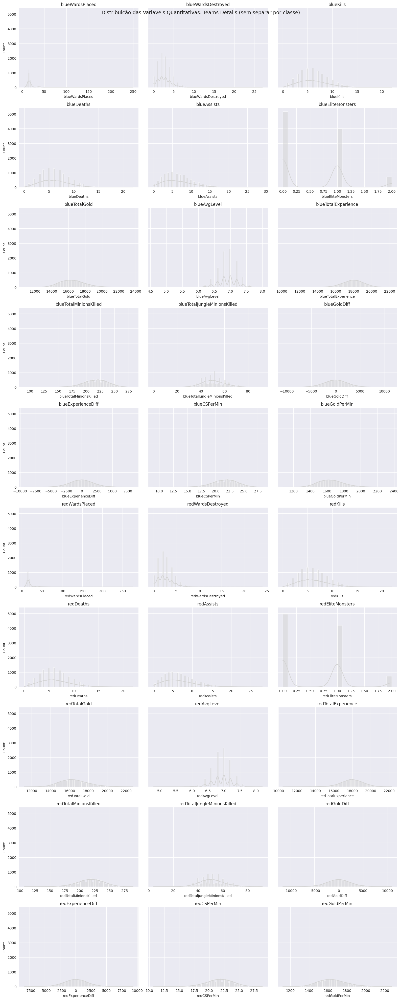

In [16]:
import math

num_cols = 3
num_vars = len(VARS_QUANT)
num_rows = math.ceil(num_vars / num_cols)

fig_height = 8 * (num_rows / 2) # Scale height proportionally, assuming original 8 was for 2 rows

fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, fig_height), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax_idx in range(num_vars, len(axes)): # Turn off any unused axes
    axes[ax_idx].axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Teams Details (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()




In [17]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Red Wins", COR_CONTEXTO), ("Blue Wins", COR_DESTAQUE)]):
        subset = df[df["blueWins"] == j]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: BlueWins (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"? Sim. As maiores diferenças aparecem principalmente em GoldDiff e ExperienceDiff. Quando o time azul vence, essas distribuições se deslocam para valores positivos e quando perde, ficam mais concentradas em valores negativos. Kills, deaths, ouro total e experiência também apresentam deslocamentos entre as classes. Já variáveis relacionadas a wards parecem ter distribuições bastante semelhantes, indicando menor poder de separação entre vitória e derrota.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9879.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — blueTotalGold: estatística=0.9882, p-valor=8.201e-28
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


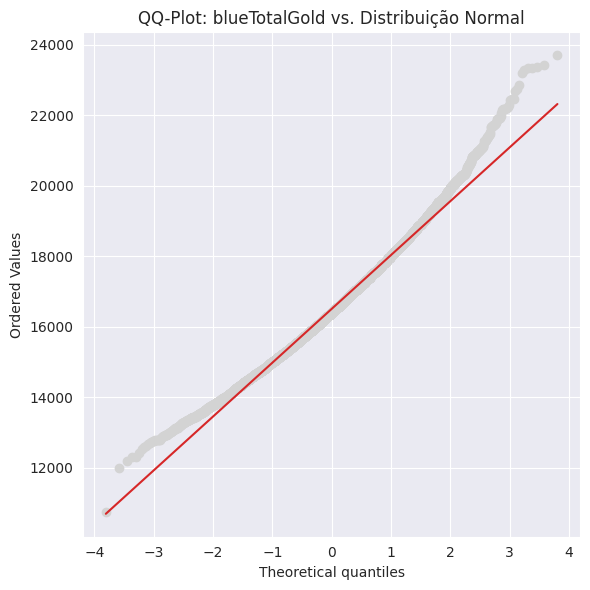

In [18]:
stat_sw, p_valor_sw = stats.shapiro(df["blueTotalGold"].dropna())
print(f"Shapiro-Wilk — blueTotalGold: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — blueTotalGold"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["blueTotalGold"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: blueTotalGold vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [24]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9879.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
blueWardsPlaced,0.5362,0.000000,True
blueWardsDestroyed,0.7929,0.000000,True
blueKills,0.9724,0.000000,True
blueDeaths,0.9740,0.000000,True
blueAssists,0.9496,0.000000,True
blueEliteMonsters,0.7325,0.000000,True
blueTotalGold,0.9882,0.000000,True
blueAvgLevel,0.9557,0.000000,True
blueTotalExperience,0.9952,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="blueTotalGold", hue="blueWins",
             palette={0: COR_CONTEXTO, 1: COR_DESTAQUE})
plt.title("ECDF — Blue Total Gold por Blue Wins")
plt.xlabel("Blue Total Gold")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

Conseguimos perceber que o total de gold que o time azul possui influencia na sua vitoria

### Métricas de Tendêncial Central

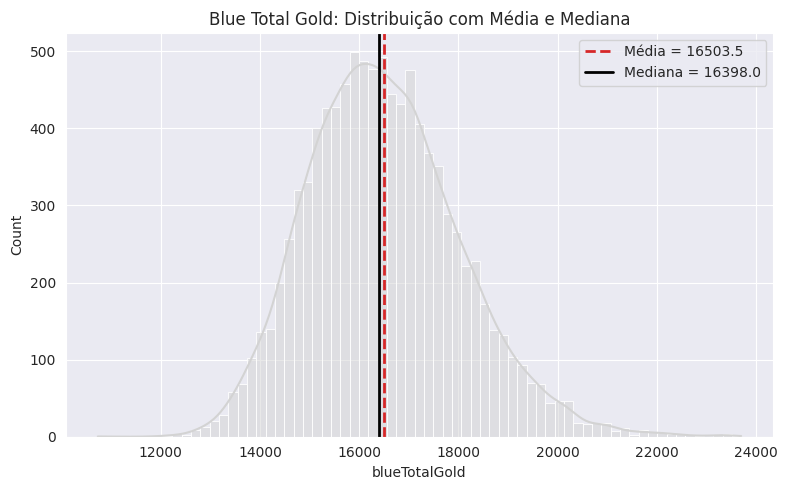

In [19]:
media_gold = df["blueTotalGold"].mean()
mediana_gold = df["blueTotalGold"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="blueTotalGold", kde=True, color=COR_NEUTRA)
plt.axvline(media_gold, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_gold:.1f}")
plt.axvline(mediana_gold, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_gold:.1f}")
plt.title("Blue Total Gold: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

Conseguimos perceber que possui um grau pouco de assimetria

### Dispersão




In [20]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {0: COR_CONTEXTO, 1: COR_DESTAQUE} # Updated to use 0 and 1 for blueWins

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="blueWins", y=col, hue="blueWins", # Changed to 'blueWins'
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="blueWins", y=col, hue="blueWins", # Changed to 'blueWins'
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot (Blue Wins)", fontsize=14) # Updated title
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.: Sim. GoldDiff e ExperienceDiff são os exemplos mais evidentes: o intervalo interquartil das partidas vencidas aparece claramente em valores mais altos do que o das derrotas. Kills, ouro total e experiência também seguem esse padrão, enquanto deaths apresenta o comportamento inverso. Isso já sugere, antes de uma análise estatística formal, que essas variáveis podem ser úteis para distinguir vitórias e derrotas.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [21]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
blueWardsPlaced,5.00,29.00,1627.0
blueWardsDestroyed,-3.50,8.50,136.0
blueKills,-2.00,14.00,88.0
blueDeaths,-2.00,14.00,65.0
blueAssists,-3.50,16.50,209.0
blueEliteMonsters,-1.50,2.50,0.0
blueTotalGold,12350.25,20524.25,114.0
blueAvgLevel,6.20,7.80,69.0
blueTotalExperience,14834.00,21058.00,107.0
blueTotalMinionsKilled,157.00,277.00,61.0


### Visualizando os Outliers




In [22]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover. A maior parte dos outliers parece ser estatística e plausível dentro do jogo, representando partidas excepcionalmente desequilibradas, portanto não faria sentido removê-los apenas por estarem fora do IQR. Entretanto, WardsPlaced chama atenção: existem partidas com 250 ou mais wards, muito acima da mediana de 16. Esses casos precisam ser investigados com base nas regras do jogo e na forma como o dataset foi coletado. Se forem registros válidos, devem ser mantidos ou tratados com transformação porem se forem erros de coleta, ai sim deveriam ser corrigidos ou removidos.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [46]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=["ca", "thal"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

KeyError: ['ca', 'thal']

Não será precisado tratar por conta dos dados serem todos validos e nao possuir dados ausentes


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

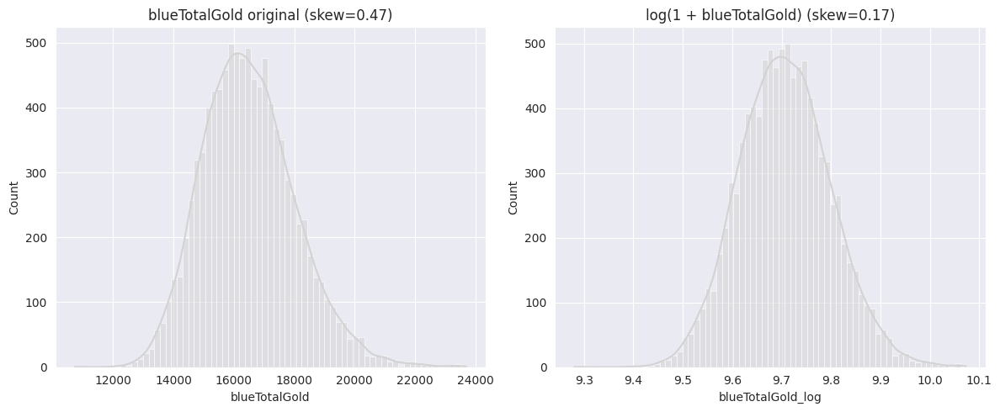

In [26]:
df["blueTotalGold_log"] = np.log1p(df["blueTotalGold"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="blueTotalGold", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"blueTotalGold original (skew={df['blueTotalGold'].skew():.2f})")

sns.histplot(data=df, x="blueTotalGold_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + blueTotalGold) (skew={df['blueTotalGold_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)? Sim. A transformação logarítmica reduziu a assimetria do blueTotalGold: o skewness caiu de 0,47 para 0,17, deixando a distribuição mais próxima da simetria. Porem, como a distribuição original já apresentava apenas uma assimetria moderada, a transformação não seria necessariamente indispensável. Ela poderia ser útil caso precisássemos atender melhor pressupostos de normalidade em alguma análise paramétrica.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [27]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
blueWardsPlaced,22.29,16.00,18.02,5.00,250.00,4.14,23.44
blueWardsDestroyed,2.82,3.00,2.17,0.00,27.00,2.85,17.20
blueKills,6.18,6.00,3.01,0.00,22.00,0.54,0.26
blueDeaths,6.14,6.00,2.93,0.00,22.00,0.51,0.21
blueAssists,6.65,6.00,4.06,0.00,29.00,0.89,1.16
blueEliteMonsters,0.55,0.00,0.63,0.00,2.00,0.69,-0.50
blueTotalGold,16503.46,16398.00,1535.45,10730.00,23701.00,0.47,0.48
blueAvgLevel,6.92,7.00,0.31,4.60,8.00,-0.34,1.12
blueTotalExperience,17928.11,17951.00,1200.52,10098.00,22224.00,-0.25,0.68
blueTotalMinionsKilled,216.70,218.00,21.86,90.00,283.00,-0.27,0.17


### Comparando "antes"x "depois""



In [28]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
blueWardsPlaced,4.136,4.136,23.439,23.439,0.0,0.0
blueWardsDestroyed,2.846,2.846,17.197,17.197,0.0,0.0
blueKills,0.539,0.539,0.264,0.264,0.0,0.0
blueDeaths,0.507,0.507,0.214,0.214,0.0,0.0
blueAssists,0.890,0.890,1.159,1.159,0.0,0.0
blueEliteMonsters,0.692,0.692,-0.503,-0.503,0.0,0.0
blueTotalGold,0.468,0.468,0.479,0.479,0.0,0.0
blueAvgLevel,-0.339,-0.339,1.116,1.116,0.0,0.0
blueTotalExperience,-0.249,-0.249,0.680,0.680,0.0,0.0
blueTotalMinionsKilled,-0.268,-0.268,0.173,0.173,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil. Não houve mudança relevante nos valores de skewness e kurtosis após o tratamento. Isso era esperado, porque removemos apenas uma pequena proporção das observações e optamos por preservar os outliers considerados plausíveis. Portanto, o tratamento foi conservador: ele melhorou a qualidade da base sem modificar artificialmente a distribuição original das variáveis.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [29]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["blueTotalGold"].dropna())
print(f"Shapiro-Wilk (antes)  — blueTotalGold: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — blueTotalGold: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — blueTotalGold: estatística=0.9882, p-valor=8.201e-28
Shapiro-Wilk (depois) — blueTotalGold: estatística=0.9882, p-valor=8.201e-28


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9879.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

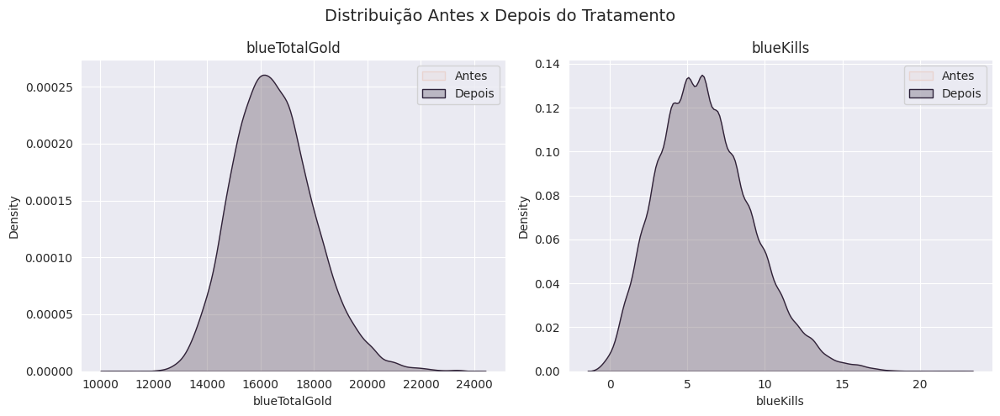

In [30]:
df_antes = df.copy() # Define df_antes to resolve NameError

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["blueTotalGold", "blueKills"]): # Changed to existing columns
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas. Sim. As distribuições antes e depois praticamente se sobrepõem, indicando que o tratamento teve pouco impacto sobre a estrutura dos dados. Isso era esperado, pois removemos poucas observações e optamos por manter os outliers considerados plausíveis. Portanto, o resultado confirma que a limpeza foi conservadora e preservou o comportamento original das variáveis.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [31]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- blueWins ---
          absoluta  relativa
blueWins                    
0             4949     0.501
1             4930     0.499
\n--- blueFirstBlood ---
                absoluta  relativa
blueFirstBlood                    
1                   4987     0.505
0                   4892     0.495
\n--- blueDragons ---
             absoluta  relativa
blueDragons                    
0                6303     0.638
1                3576     0.362
\n--- blueHeralds ---
             absoluta  relativa
blueHeralds                    
0                8022     0.812
1                1857     0.188
\n--- blueTowersDestroyed ---
                     absoluta  relativa
blueTowersDestroyed                    
0                        9415     0.953
1                         429     0.043
2                          27     0.003
3                           7     0.001
4                           1     0.000
\n--- redFirstBlood ---
               absoluta  relativa
redFirstBlood                   

#### Visualizando as frequências

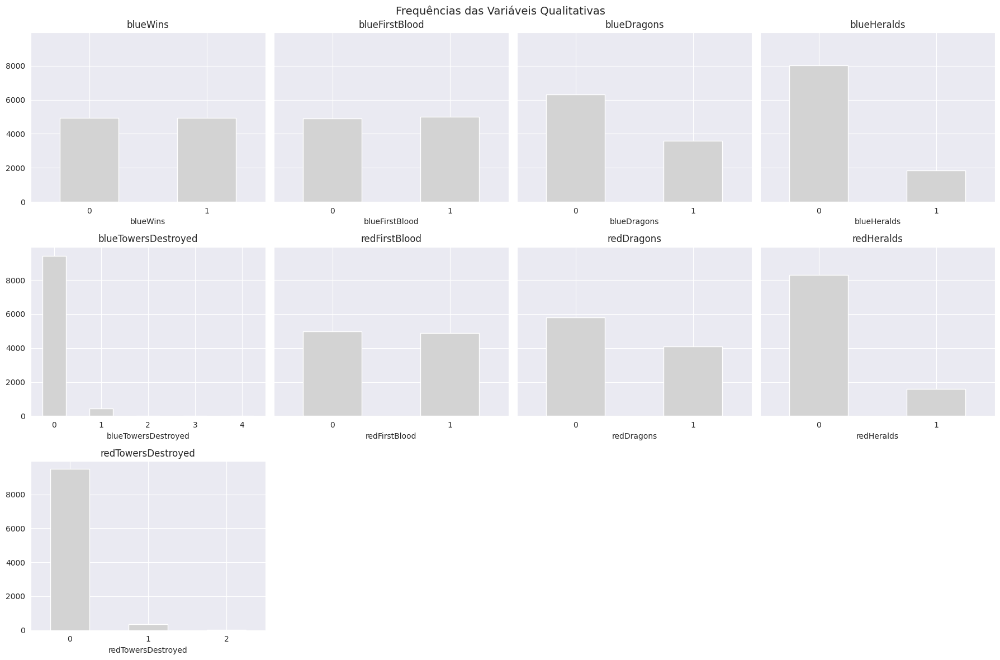

In [32]:
import math

num_vars_quali = len(VARS_QUALI)
num_cols = 4
num_rows = math.ceil(num_vars_quali / num_cols)

fig_height = 8 * (num_rows / 2) # Scale height proportionally based on original 2 rows

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, fig_height), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

for ax_idx in range(num_vars_quali, len(axes)): # Turn off any unused axes
    axes[ax_idx].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada. Sim. As variáveis mais desbalanceadas são TowersDestroyed e Heralds, nas quais a categoria 0 concentra a grande maioria das observações. Dragons também apresenta certo desequilíbrio, porém menos intenso. Em contraste, a variável alvo blueWins está praticamente balanceada. Na análise bivariada, precisamos ter cuidado principalmente com as categorias muito raras, porque uma diferença percentual aparentemente grande pode ser baseada em poucas observações.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [33]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI # Removed 'doenca_cardiaca' as it's not in the current dataset
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
blueWins,2.0,1.00,1.000
blueFirstBlood,2.0,1.02,1.000
blueDragons,2.0,1.76,0.944
blueHeralds,2.0,4.32,0.697
blueTowersDestroyed,5.0,9415.00,0.127
redFirstBlood,2.0,1.02,1.000
redDragons,2.0,1.42,0.978
redHeralds,2.0,5.25,0.634
redTowersDestroyed,3.0,327.00,0.163


Rodar Dpeois blueTowersDestroyed

**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente? Sim. blueTowersDestroyed e redTowersDestroyed apresentam entropia muito próxima de zero, indicando forte concentração em uma única categoria, principalmente zero torres destruídas. Já a variável alvo blueWins apresenta entropia igual a 1 e razão de desbalanceamento igual a 1, mostrando que vitórias e derrotas estão praticamente perfeitamente balanceadas. Portanto, o alvo não apresenta um problema de desbalanceamento de classes.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

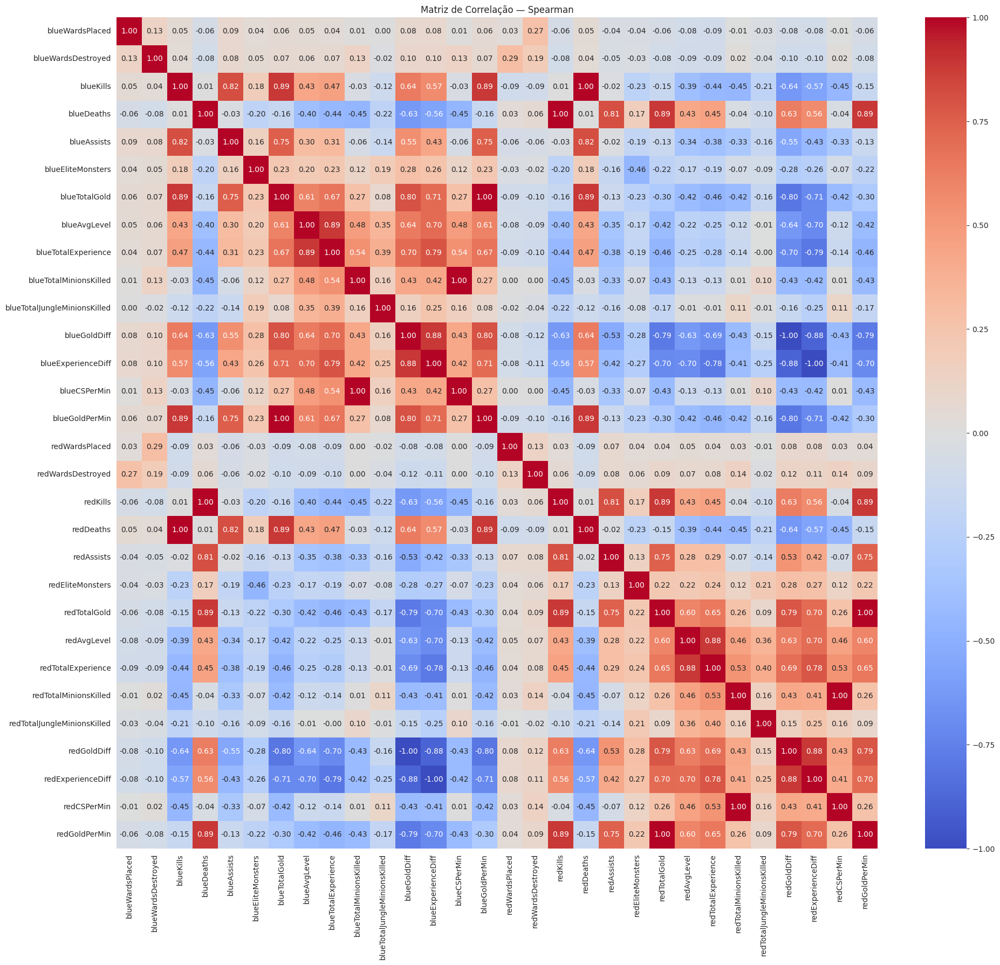

In [34]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

fig, ax = plt.subplots(1,figsize=(20, 18),sharey=True)
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de Correlação — Spearman")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

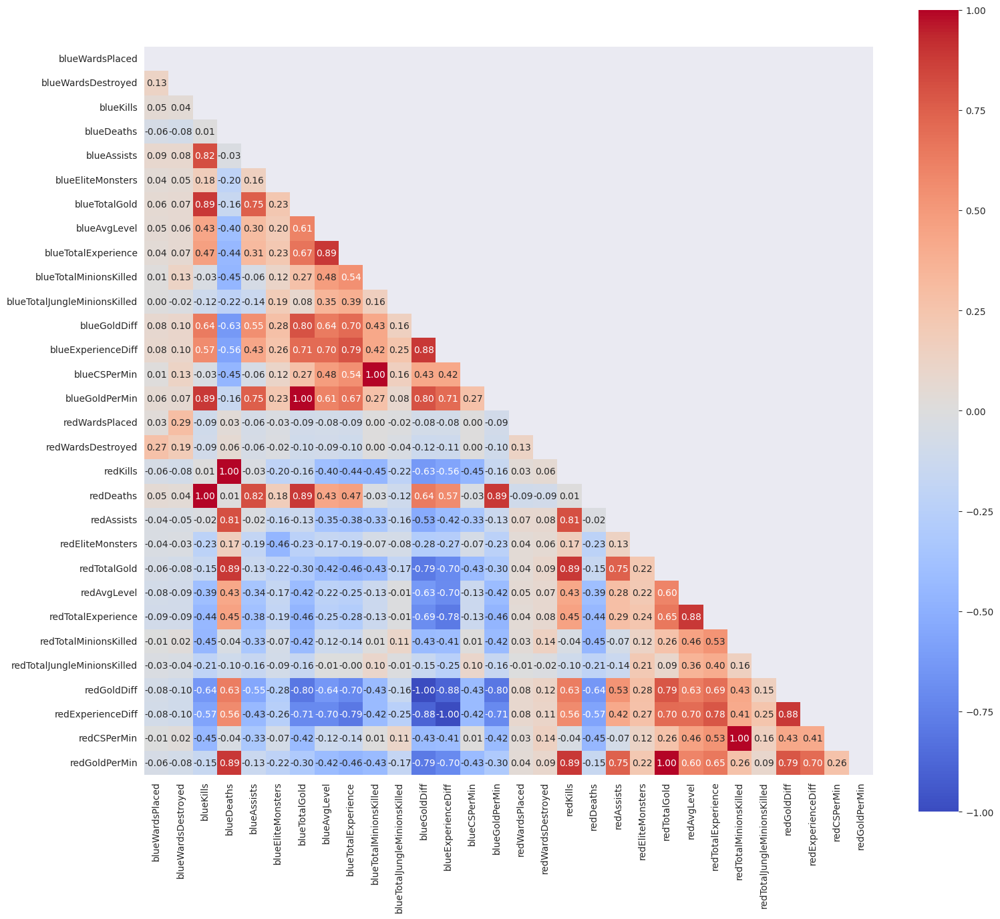

In [35]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(16, 14))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não. Não observamos divergências expressivas entre Pearson e Spearman. As correlações mais fortes permanecem com magnitudes e sinais muito semelhantes nos dois métodos. Isso sugere que as principais relações entre as variáveis são aproximadamente lineares, e não apenas monotônicas não lineares.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

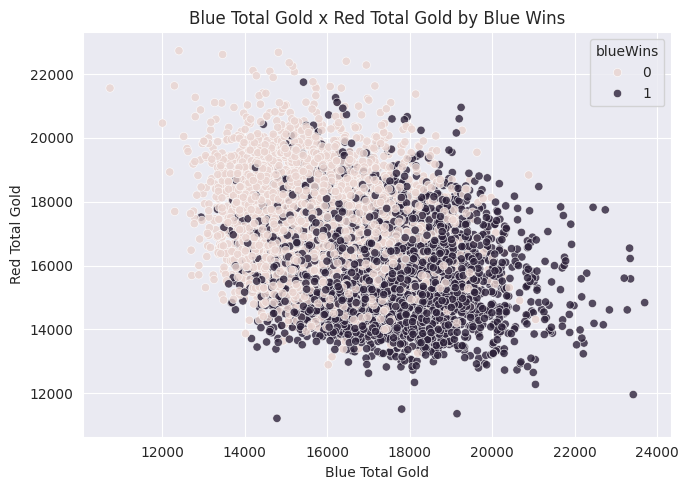

In [36]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="blueTotalGold", y="redTotalGold", hue="blueWins",
                palette={0: COR_CONTEXTO, 1: COR_DESTAQUE}, alpha=0.8)
plt.title("Blue Total Gold x Red Total Gold by Blue Wins")
plt.xlabel("Blue Total Gold")
plt.ylabel("Red Total Gold")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas? Sim. Observamos uma tendência de separação entre vitórias e derrotas. Quando o time azul possui mais ouro e o vermelho menos ouro, predominam as vitórias do azul e no cenário inverso, predominam as derrotas. Entretanto, existe sobreposição quando os valores de ouro dos dois times são próximos, então apenas o ouro total de cada equipe não separa perfeitamente as classes.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [37]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_0 = df.loc[df["blueWins"] == 0, col]
    grupo_1 = df.loc[df["blueWins"] == 1, col]

    stat_t, p_t = stats.ttest_ind(grupo_0, grupo_1, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_0, grupo_1)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
blueWardsPlaced,0.99310,0.00001,False
blueWardsDestroyed,0.00001,0.00000,True
blueKills,0.00000,0.00000,True
blueDeaths,0.00000,0.00000,True
blueAssists,0.00000,0.00000,True
blueEliteMonsters,0.00000,0.00000,True
blueTotalGold,0.00000,0.00000,True
blueAvgLevel,0.00000,0.00000,True
blueTotalExperience,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado. Os testes concordam na grande maioria das variáveis, indicando diferenças significativas entre vitórias e derrotas. A principal divergência ocorre em blueWardsPlaced: o T-Test não encontra diferença significativa, enquanto o Mann–Whitney encontra. Como essa variável apresenta forte assimetria e cauda pesada, priorizamos o Mann–Whitney, que é mais coerente com as características observadas nos dados.

ANOVA          — blueTotalGold entre categorias de blueTowersDestroyed: estatística=353.846, p-valor=3.7329e-285
Kruskal-Wallis — blueTotalGold entre categorias de blueTowersDestroyed: estatística=785.166, p-valor=1.2542e-168


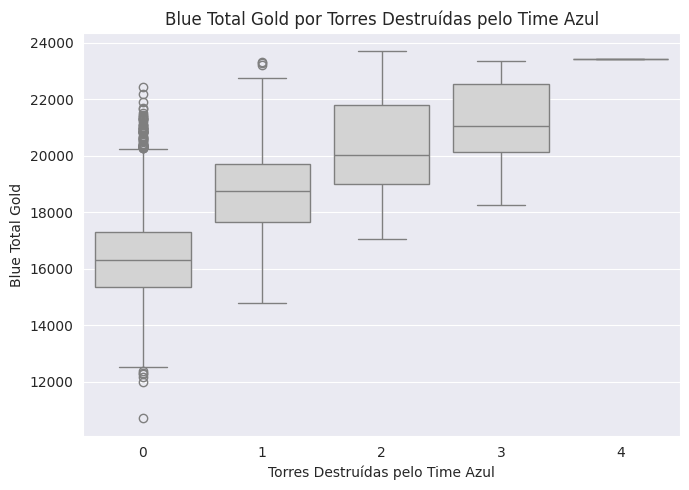

In [38]:
grupos_towers = [grupo["blueTotalGold"].values for _, grupo in df.groupby("blueTowersDestroyed")]

stat_anova, p_anova = stats.f_oneway(*grupos_towers)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_towers)          # não-paramétrico

print(f"ANOVA          — blueTotalGold entre categorias de blueTowersDestroyed: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — blueTotalGold entre categorias de blueTowersDestroyed: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="blueTowersDestroyed", y="blueTotalGold", color=COR_NEUTRA)
plt.title("Blue Total Gold por Torres Destruídas pelo Time Azul")
plt.xlabel("Torres Destruídas pelo Time Azul")
plt.ylabel("Blue Total Gold")
plt.tight_layout()
plt.show()

# A partir daqui foi o que eu não completei(eu tinha feito até acima mas eu tinha falado com Menezes ele tinha dito que era opcional ai foi quando eu mandei a mensagem no class) e parei por aqui

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste. Sim. O Kruskal–Wallis concorda com a ANOVA: há diferença estatisticamente significativa no ouro total do time azul entre as categorias de torres destruídas. Visualmente também observamos uma tendência crescente, em que equipes que destruíram mais torres apresentam maior quantidade de ouro. Como estamos priorizando uma abordagem não paramétrica diante das características das distribuições, reportaríamos o Kruskal–Wallis como resultado principal e a ANOVA apenas como contraste.

#### Quantitativa x Qualitativa

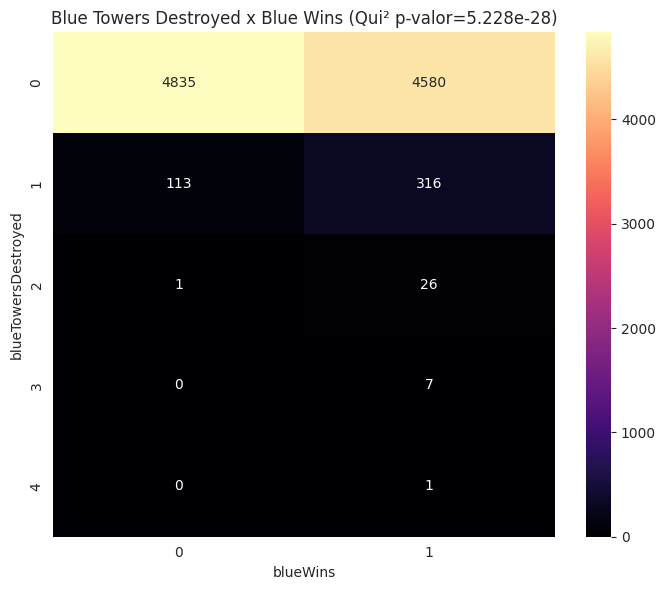

In [39]:
contingencia_towers = pd.crosstab(df["blueTowersDestroyed"], df["blueWins"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_towers)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(contingencia_towers, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Blue Towers Destroyed x Blue Wins (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

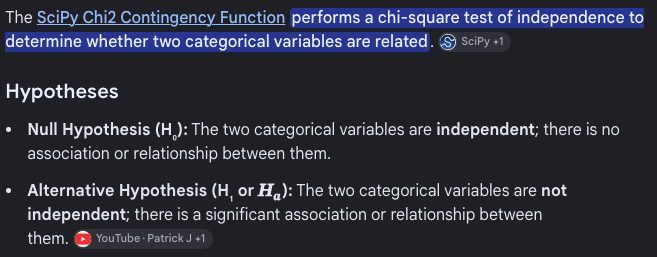O p-valor do Qui-Quadrado é extremamente baixo, então rejeitamos a hipótese de independência. Existe associação estatisticamente significativa entre o número de torres destruídas pelo time azul e a vitória. Observamos ainda que a proporção de vitórias aumenta conforme cresce o número de torres destruídas.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [40]:
df["team_label"] = df["blueWins"].map({0: "Red Team", 1: "Blue Team"})
df["avg_level_band"] = pd.cut(df["blueAvgLevel"], bins=[0, 6.8, 7.0, 7.2, 8.5],
                             labels=["low", "mid-low", "mid-high", "high"])

print("Desbalanceamento — team_label:")
print(metrica_desbalanceamento(df["team_label"]))
print("\nDesbalanceamento — avg_level_band:")
print(metrica_desbalanceamento(df["avg_level_band"]))

Desbalanceamento — team_label:
n_classes                 2.0
razao_desbalanceamento    1.0
entropia_normalizada      1.0
dtype: float64

Desbalanceamento — avg_level_band:
n_classes                 4.000
razao_desbalanceamento    5.180
entropia_normalizada      0.889
dtype: float64


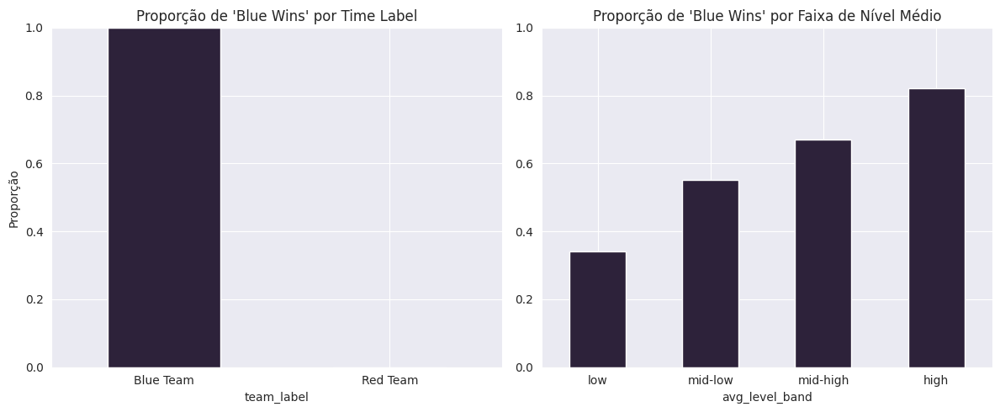

In [41]:
prop_by_team_label = pd.crosstab(df["team_label"], df["blueWins"], normalize="index").round(3)
prop_by_avg_level_band = pd.crosstab(df["avg_level_band"], df["blueWins"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_by_team_label[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de 'Blue Wins' por Time Label")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_by_avg_level_band[1].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de 'Blue Wins' por Faixa de Nível Médio")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade. A faixa de nível médio mostra uma diferença bastante clara na proporção de vitórias: quanto maior o nível médio do time azul, maior a frequência de blueWins. Isso sugere que vantagem de experiência e nível está associada ao resultado da partida. Já team_label precisa ser interpretada com cuidado: se ela foi construída a partir de blueWins, o padrão de 100% para Blue Team e 0% para Red Team é consequência direta da definição da variável, e não uma descoberta analítica.

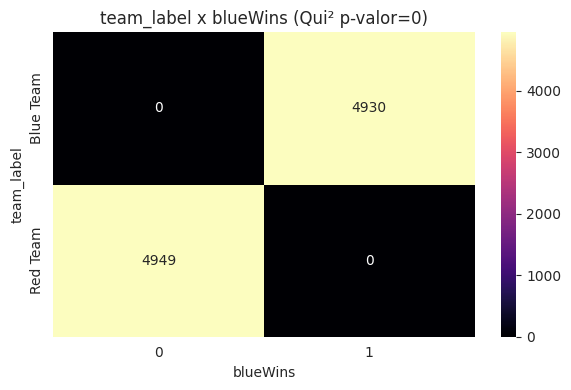

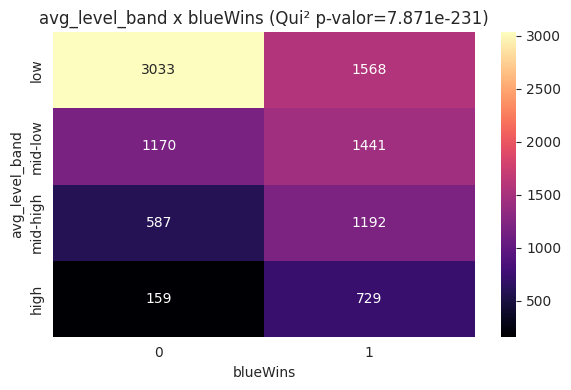

In [42]:
for atributo in ["team_label", "avg_level_band"]:
    contingencia = pd.crosstab(df[atributo], df["blueWins"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x blueWins (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness. O Qui-Quadrado indica associação estatisticamente significativa entre a faixa de nível médio e a vitória do time azul. A proporção de vitórias cresce de aproximadamente 34% na faixa de nível mais baixa para 82% na mais alta, mostrando uma associação forte entre vantagem de nível e resultado da partida. Já team_label apresenta associação perfeita com blueWins, mas isso ocorre porque a variável foi derivada do próprio resultado da partida; portanto, ela caracteriza target leakage e não deve ser utilizada como variável explicativa em um modelo.

#### Outliers bivariados

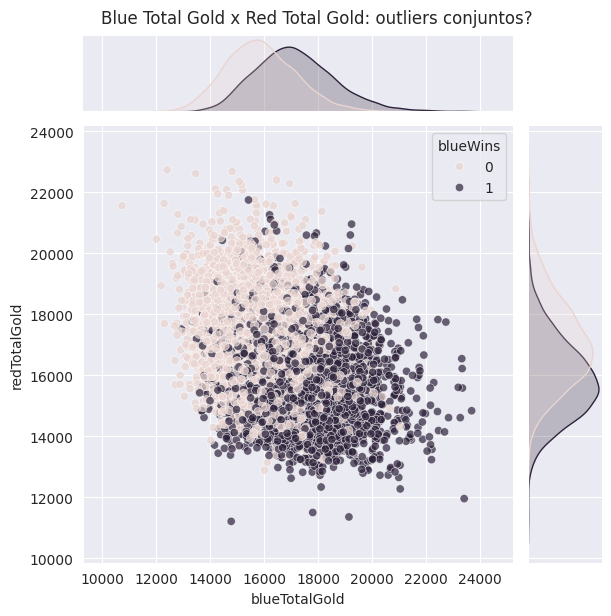

In [43]:
sns.jointplot(data=df, x="blueTotalGold", y="redTotalGold", hue="blueWins",
              palette={0: COR_CONTEXTO, 1: COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Blue Total Gold x Red Total Gold: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`? Sim. O gráfico mostra que alguns valores podem ser comuns quando analisados separadamente, mas incomuns quando considerados em conjunto. Por exemplo, partidas em que os dois times apresentam simultaneamente valores elevados de ouro podem não ser outliers em nenhuma variável isolada, mas representam uma combinação pouco frequente no espaço bivariado. Isso caracteriza um possível outlier multivariado.

#### Análise Multivariada

##### Matriz de Correlação

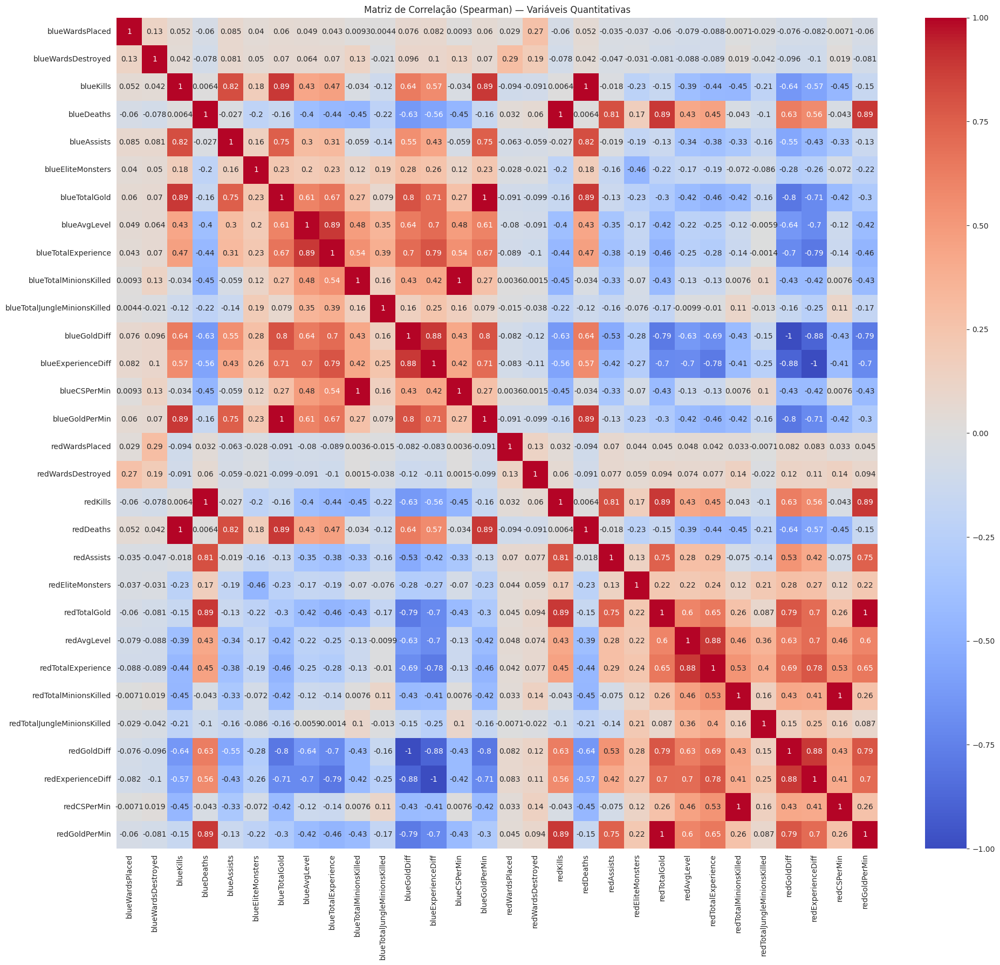

In [44]:
plt.figure(figsize=(20, 18))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

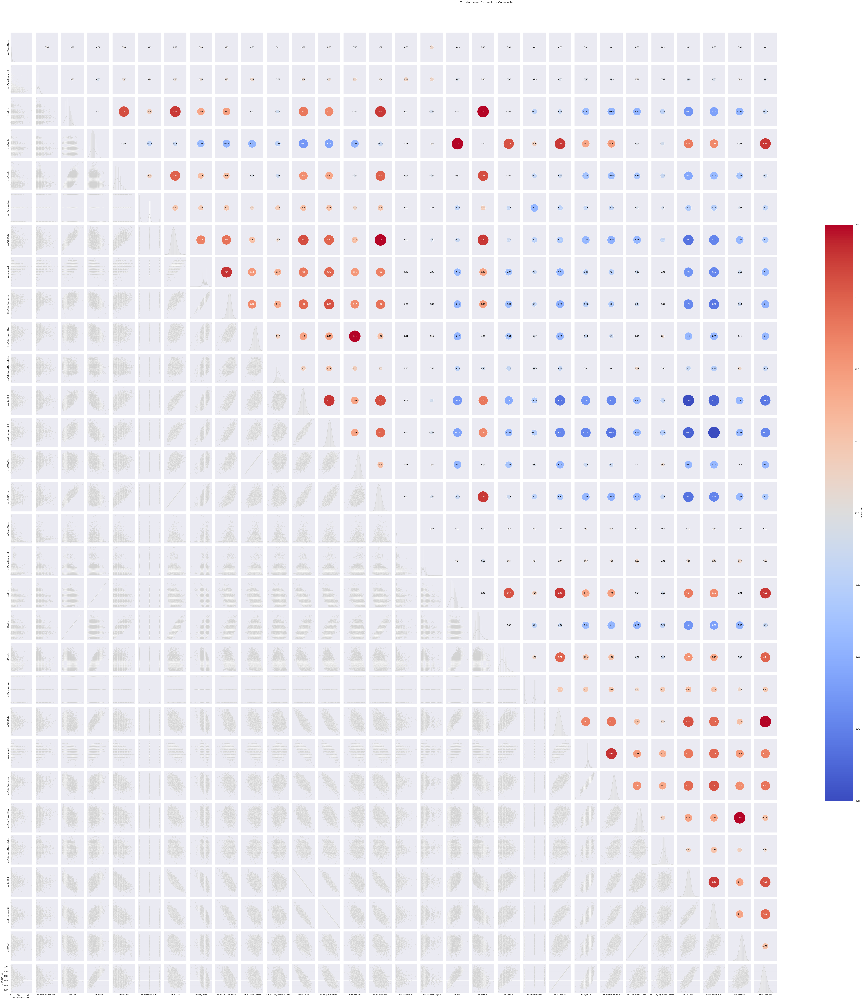

In [45]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.


